# Optimization in Several Variables

Find the minimum or maximum of $f(x, y)$.

| | exact (SymPy) | numerical (NumPy / SciPy) |
|---|---|---|
| **several variables** $f(x, y)$ | solve $\nabla f = \mathbf{0}$, Hessian test | grid search, `minimize` |

**Maximize = minimize the negative:** $\max f = -\min(-f)$. The numerical tools only minimize.

In [1]:
import sympy as sp
import numpy as np
from scipy.optimize import minimize_scalar, minimize
import matplotlib.pyplot as plt
from IPython.display import display

## Critical points and the Hessian test

For $f(x, y)$:

1. **Critical points:** solve $\nabla f = \mathbf{0}$, i.e. $f_x = 0$ and $f_y = 0$ together.
2. **Hessian test.** The Hessian is the matrix of second derivatives
$$ H = \begin{pmatrix} f_{xx} & f_{xy} \\ f_{xy} & f_{yy} \end{pmatrix}, \qquad
\begin{cases} \det H > 0,\ f_{xx} > 0 & \text{local min} \\ \det H > 0,\ f_{xx} < 0 & \text{local max} \\ \det H < 0 & \text{saddle point (neither)} \\ \det H = 0 & \text{test fails} \end{cases} $$

**Example.** $f(x, y) = x^2 + 2y^2 - 2xy - 2x$.

In [2]:
x, y = sp.symbols("x y")
f = x**2 + 2*y**2 - 2*x*y - 2*x

grad = [sp.diff(f, x), sp.diff(f, y)]
print("gradient:", grad)
crit = sp.solve(grad, [x, y], dict=True)
print("critical points:", crit)

H = sp.hessian(f, (x, y))
display(H)
for p in crit:
    Hp = H.subs(p)
    print(p, "  f =", f.subs(p), "  det H =", Hp.det(), "  f_xx =", Hp[0, 0])

gradient: [2*x - 2*y - 2, -2*x + 4*y]
critical points: [{x: 2, y: 1}]


Matrix([
[ 2, -2],
[-2,  4]])

{x: 2, y: 1}   f = -2   det H = 4   f_xx = 2


$\det H = 4 > 0$ and $f_{xx} = 2 > 0$: a **minimum** at $(2, 1)$ with $f = -2$.

**A saddle point.** $g(x, y) = x^2 - y^2$ has $\nabla g = \mathbf{0}$ at the origin, but it goes up along $x$ and down along $y$: neither a max nor a min.

In [3]:
g = x**2 - y**2
print("critical points:", sp.solve([sp.diff(g, x), sp.diff(g, y)], [x, y], dict=True))
print("det H =", sp.hessian(g, (x, y)).det())

critical points: [{x: 0, y: 0}]
det H = -4


**3D picture of the saddle.** `fig.add_subplot(projection="3d")` makes 3D axes; `ax.plot_surface(X, Y, Z)` draws the graph $z = g(x, y)$.

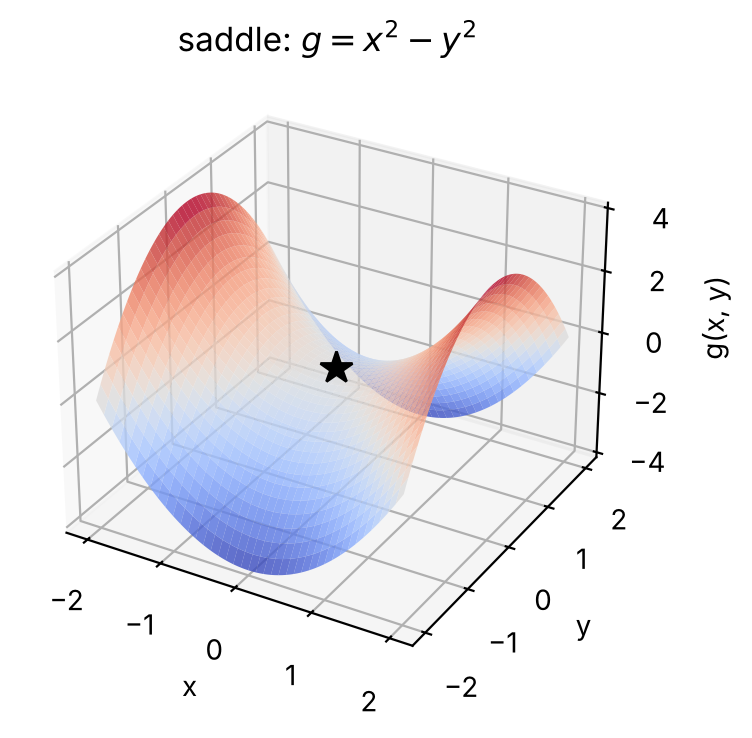

In [4]:
Xs, Ys = np.meshgrid(np.linspace(-2, 2, 81), np.linspace(-2, 2, 81))
G = Xs**2 - Ys**2

fig = plt.figure(figsize=(5, 4))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(Xs, Ys, G, cmap="coolwarm", alpha=0.8)
ax.plot([0], [0], [0], "k*", markersize=12, zorder=5)
ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("g(x, y)")
ax.set_title("saddle: $g = x^2 - y^2$")
plt.show()

**NumPy: picture and grid search.** `np.meshgrid` makes a grid of $(x, y)$ points. Two ways to picture $f$:

- **contour plot** (`ax.contour`): the level curves $f = $ const,
- **density plot** (`ax.pcolormesh`): each point coloured by its value of $f$; the **colorbar** (`fig.colorbar`) shows which colour means which value.

`plt.subplots(1, 2)` gives a figure with two axes side by side.

grid min: x = 2.0   y = 1.0   f = -2.0


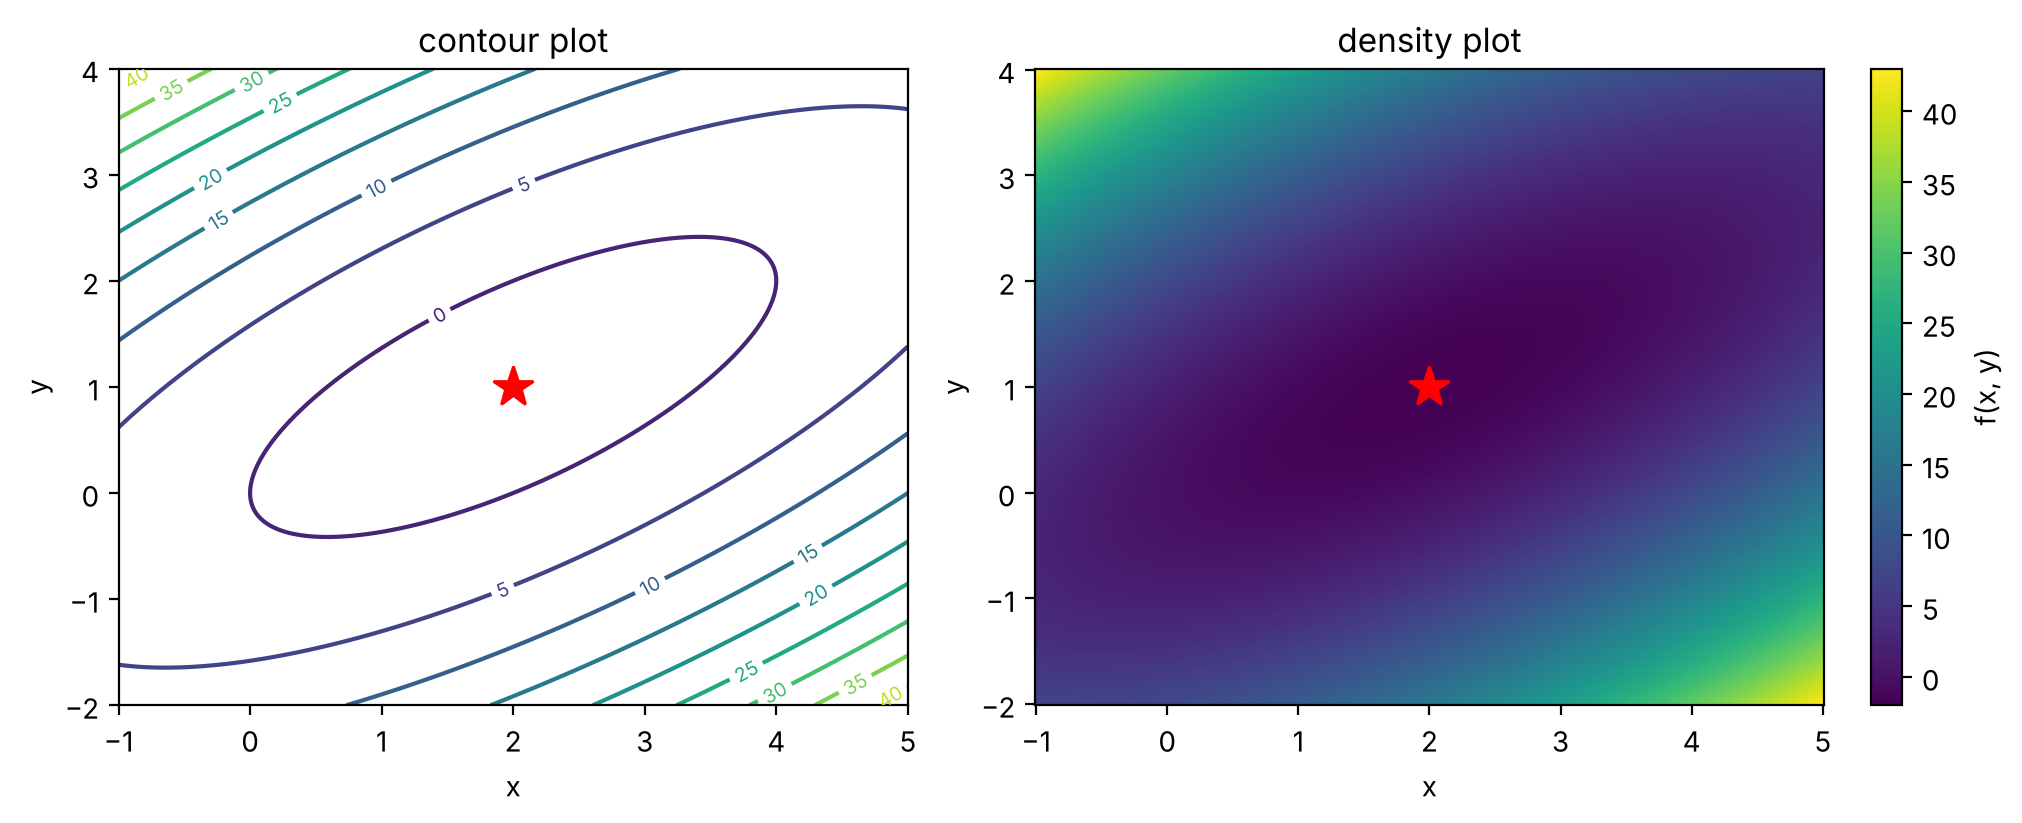

In [5]:
xs = np.linspace(-1, 5, 301)
ys = np.linspace(-2, 4, 301)
X, Y = np.meshgrid(xs, ys)
F = X**2 + 2*Y**2 - 2*X*Y - 2*X

i = np.argmin(F)                              # position in the flattened grid
print("grid min: x =", X.flat[i], "  y =", Y.flat[i], "  f =", F.flat[i])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")

cs = ax1.contour(X, Y, F, levels=10, cmap="viridis")
ax1.clabel(cs, fontsize=7)
# fig.colorbar(cs, ax=ax1, label="f(x, y)")
ax1.set_title("contour plot")

pm = ax2.pcolormesh(X, Y, F, cmap="viridis", shading="auto")
fig.colorbar(pm, ax=ax2, label="f(x, y)")
ax2.set_title("density plot")

for ax in (ax1, ax2):
    ax.plot(2, 1, "r*", markersize=15)
    ax.set_xlabel("x"); ax.set_ylabel("y")
plt.show()

**3D surface plot.** The same function as a surface $z = f(x, y)$, with the minimum marked. `ax.view_init(elev, azim)` turns the camera.

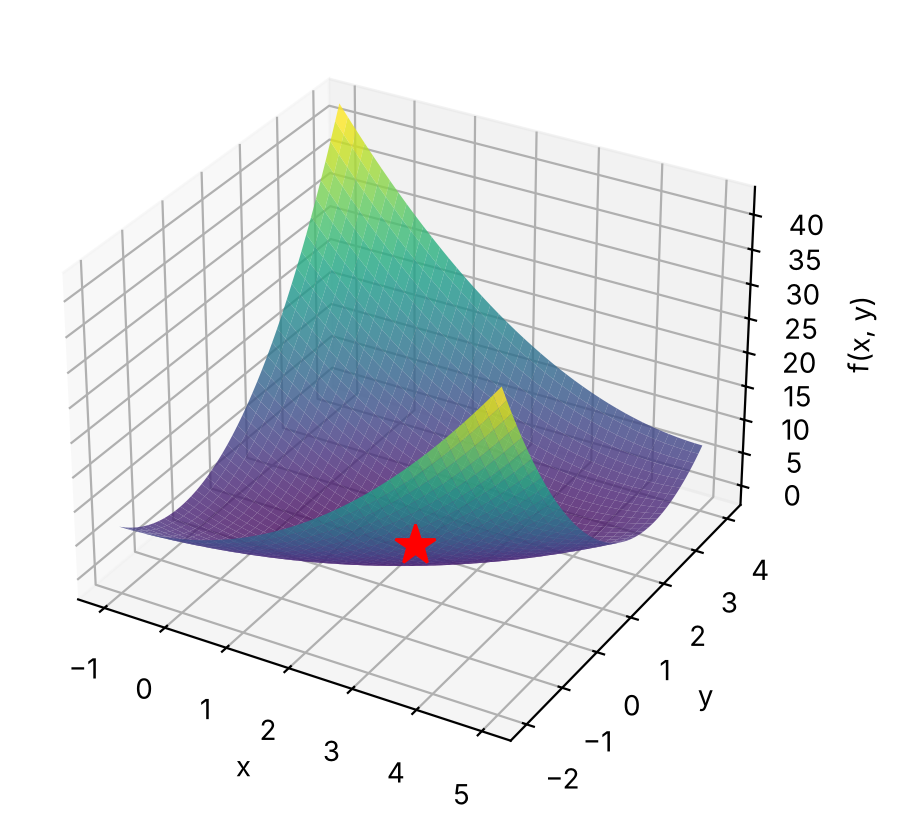

In [6]:
fig = plt.figure(figsize=(6, 5))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(X, Y, F, cmap="viridis", alpha=0.8)
ax.plot([2], [1], [-2], "r*", markersize=15, zorder=5)
ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("f(x, y)")
ax.view_init(elev=30, azim=-60)
plt.show()

**SciPy: `minimize(fun, x0)`.** The function takes **one array** `v` holding all the variables: `v[0]` is $x$, `v[1]` is $y$. `x0` is a starting guess. It works the same way for any number of variables. To maximize, minimize $-f$.

In [7]:
fn = lambda v: v[0]**2 + 2*v[1]**2 - 2*v[0]*v[1] - 2*v[0]

res = minimize(fn, x0=[0, 0])
print("x, y =", res.x, "   f =", res.fun)

x, y = [1.99999988 0.99999999]    f = -1.9999999999999867


### Summary

| | SymPy | NumPy / SciPy |
|---|---|---|
| partial derivatives | `sp.diff(f, x)`, `sp.diff(f, y)` | |
| critical points | `sp.solve([f_x, f_y], [x, y], dict=True)` | |
| Hessian | `sp.hessian(f, (x, y))` | |
| grid search | | `np.meshgrid`, `np.argmin`, `X.flat[i]` |
| 2D plots | | `ax.contour`, `ax.pcolormesh`, `fig.colorbar` |
| 3D plot | | `ax = fig.add_subplot(projection="3d")`; `ax.plot_surface(X, Y, F)` |
| min of $f(x, y)$ | Hessian test at each critical point | `minimize(f, x0=[0, 0])` |
| maximize | minimize $-f$ | minimize $-f$ |

## Exercises

Solve with **SymPy** (exact) and with **NumPy/SciPy** (numerical).

**Syntax you will need:**

| task | SymPy | NumPy / SciPy |
|---|---|---|
| variables | `x, y = sp.symbols("x y")` | |
| positive variables | `x, y = sp.symbols("x y", positive=True)` | |
| exponential | `sp.exp(x)` | `np.exp(t)` |
| simplify | `sp.simplify(expr)` | |
| derivative | `sp.diff(f, x)` | |
| solve equations | `sp.solve(eqs, [x, y], dict=True)` | |
| substitute | `f.subs({x: 2, y: 1})` | |
| Hessian | `sp.hessian(f, (x, y))` | |
| matrix entry, determinant | `H[0, 0]`, `H.det()` | `H[0, 0]`, `np.linalg.det(H)` |
| function of several variables | | `fn = lambda v: v[0]**2 + v[1]**2` |
| 2D grid | | `X, Y = np.meshgrid(xs, ys)` |
| contour plot | | `cs = ax.contour(X, Y, F, levels=10)` |
| density plot | | `pm = ax.pcolormesh(X, Y, F, shading="auto")` |
| colorbar | | `fig.colorbar(pm, ax=ax)` |
| 3D axes | | `fig = plt.figure()`; `ax = fig.add_subplot(projection="3d")` |
| surface plot | | `ax.plot_surface(X, Y, F, cmap="viridis")` |
| min of $f(x, y)$ | | `minimize(fn, x0=[0, 0])` |

**Exercise 1 (a max and a min).** Let $f(x, y) = x\,e^{-(x^2 + y^2)}$.

(a) In **SymPy**, find both critical points and classify each with the Hessian test. Use `sp.exp` for $e$, and `sp.simplify` to tidy the answers.

(b) With SciPy, find the minimum (minimize $f$) and the maximum (minimize $-f$), both starting from $(0, 0)$. Then minimize $f$ starting from $(3, 0)$. What happens, and why? (Hint: how big is $f$, and how steep is it, near $(3, 0)$?)

(c) In **NumPy**, evaluate $f$ on a grid over $[-2, 2] \times [-2, 2]$ (`np.meshgrid`, `np.exp`) and make a **density plot** with `ax.pcolormesh` and a colorbar. Mark the max and the min.

In [8]:
# Exercise 1

**Exercise 2 (an open box).** An open box (no lid) with a rectangular base $x \times y$ and height $z$ must hold $32\ \text{cm}^3$. The material used is its surface area, which is
$$ S(x, y) = xy + \frac{64}{x} + \frac{64}{y}, \qquad x, y > 0. $$

(a) In **SymPy**, find the critical point (declare `x, y = sp.symbols("x y", positive=True)` so SymPy keeps only positive solutions) and show with the Hessian test that it is a minimum. What are the dimensions of the box (the height is $z = 32/(xy)$), and how much material does it use?

(b) Check with SciPy's `minimize`, starting from $(1, 1)$, and make a **contour plot** on $[1, 10] \times [1, 10]$ with the point marked.

In [9]:
# Exercise 2